# Fig. 3: performance of 12 PAA estimators (3 training seeds).

- (a) Regression RMSE: off-recipe (closed-loop) test as filled dots (seed mean, min-max bar) and recipe-based test as open dots.
- (b) Predicted vs. true PAA on the off-recipe test (seed 0) for representative models: PLS and the best point-wise ML, sequence DL and Transformer-family models (chosen by seed-mean off-recipe RMSE).
- (c) Toxicity classification (PAA > 2,400 mg/L, same threshold applied to the regression output): ROC-AUC and F1 (seed mean, min-max bar).
- (d) SHAP beeswarm for the Patch Transformer.
Inputs: paa_bench_pred_s{0,1,2}{TAG}.npz and paa_shap_patch_s{0,1,2}{TAG}.npz.
Style: 17 x 11 cm, DejaVu Sans, title 6.5 / text 5.5 pt, ink #23201a, grey #8f897d.

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import os, numpy as np, matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from sklearn.metrics import roc_auc_score, f1_score
R = DATA; OUT = OUTD + 'fig3'
INK, GRY, FILL = '#23201a', '#8f897d', '#f4f2ee'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5,
                     'axes.labelsize': 5.5, 'xtick.labelsize': 5.0, 'ytick.labelsize': 5.5, 'axes.linewidth': 0.5,
                     'xtick.major.width': 0.5, 'ytick.major.width': 0.5, 'xtick.major.size': 2, 'ytick.major.size': 0,
                     'mathtext.default': 'regular'})
M = ['Ridge', 'PLS', 'RandomForest', 'HGB', 'MLP', 'GRU', 'LSTM', 'TCN', 'Transformer-S', 'Transformer-L', 'Transformer+cum', 'Patch-Transformer']
NAME = {'Ridge': 'Ridge', 'PLS': 'PLS', 'RandomForest': 'Random forest', 'HGB': 'Gradient boosting', 'MLP': 'MLP', 'GRU': 'GRU',
        'LSTM': 'LSTM', 'TCN': 'TCN', 'Transformer-S': 'Transformer-S', 'Transformer-L': 'Transformer-L',
        'Transformer+cum': 'Transformer + cumulative', 'Patch-Transformer': 'Patch Transformer'}
GROUPS = [('Ridge', 'PLS'), ('RandomForest', 'HGB', 'MLP'), ('GRU', 'LSTM', 'TCN'), ('Transformer-S', 'Transformer-L', 'Transformer+cum', 'Patch-Transformer')]
TAG = os.environ.get('PRED_TAG', '_indep')                                    # independent off-recipe test set
Z = [np.load(R + f'paa_bench_pred_s{s}{TAG}.npz') for s in range(3)]
def met(z, m):
    yv, yc = z['y_var'], z['y_cl']; pv, pc = z[f'{m}|var'], z[f'{m}|cl']
    a, b = np.isfinite(yv) & np.isfinite(pv), np.isfinite(yc) & np.isfinite(pc)
    return dict(rv=np.sqrt(np.mean((pv[a] - yv[a]) ** 2)), rc=np.sqrt(np.mean((pc[b] - yc[b]) ** 2)),
                auc=roc_auc_score(yc[b] > 2400, pc[b]), f1=f1_score(yc[b] > 2400, pc[b] > 2400))
S = {m: {k: np.array([met(z, m)[k] for z in Z]) for k in ('rv', 'rc', 'auc', 'f1')} for m in M}
best = lambda c: min(c, key=lambda m: S[m]['rc'].mean())
REP = [('PLS', 'PLS'), (best(['Ridge', 'PLS']), None), (best(['RandomForest', 'HGB', 'MLP']), None), (best(['GRU', 'LSTM', 'TCN']), None),
       (best(['Transformer-S', 'Transformer-L', 'Transformer+cum', 'Patch-Transformer']), None)]
REP = list(dict.fromkeys(m for m, _ in REP))                                  # drop duplicate if PLS is also the best linear model
REP = [m for m in REP if m != 'Ridge']                                      # Ridge is not shown in (b)
print('representative models', REP)
# row positions: 0.6 gap between model groups
ypos, y = {}, 0.0
for g in GROUPS:
    for m in g: ypos[m] = y; y += 1
    y += 0.6
YMAX = y - 0.6
fig = plt.figure(figsize=(17 / 2.54, 11 / 2.54), facecolor='white')
gs = GridSpec(2, 2, figure=fig, width_ratios=[1, 1.05], height_ratios=[1, 0.85], wspace=0.19, hspace=0.42,
              left=0.175, right=0.985, top=0.95, bottom=0.08)
def style(ax):
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): ax.spines[sp].set_color(INK)
    ax.tick_params(colors=INK)
def rows(ax, labels=True):
    ax.set_ylim(YMAX + 0.6, -0.6); ax.set_yticks([ypos[m] for m in M])
    ax.set_yticklabels([NAME[m] for m in M] if labels else [], color=INK)
    for g in GROUPS[1:]:
        yy = ypos[g[0]] - 0.8; ax.axhline(yy, color=GRY, lw=0.4, ls=(0, (3, 2.2)), alpha=.75)
def dots(ax, key, filled=True, scale=1.0):
    for m in M:
        v = S[m][key] * scale; yy = ypos[m]
        if filled:
            ax.plot([v.min(), v.max()], [yy, yy], color=INK, lw=0.8, solid_capstyle='butt')
            ax.plot(v.mean(), yy, 'o', ms=2.6, mfc=INK, mec=INK, mew=0.5)
        else:
            ax.plot(v.mean(), yy, 'o', ms=2.6, mfc='white', mec=GRY, mew=0.7)
def title(ax, s): ax.set_title(s, loc='left', fontweight='bold', color=INK, pad=4)

representative models ['PLS', 'MLP', 'TCN', 'Patch-Transformer']


In [3]:
# (a) Regression
ax = fig.add_subplot(gs[0, 0]); style(ax); rows(ax)
dots(ax, 'rv', filled=False); dots(ax, 'rc', filled=True)
ax.set_xlabel('RMSE (mg L$^{-1}$)', color=INK); ax.set_xlim(150, 900)
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=2.6, mfc=INK, mec=INK, label='Off-recipe test'),
                   Line2D([], [], marker='o', ls='', ms=2.6, mfc='white', mec=GRY, label='Recipe test')],
          loc='lower right', frameon=False, handletextpad=0.2, borderaxespad=0.2)
title(ax, '(a)')

In [4]:
# (b) Parity plots: hexbin for representative models
sub = GridSpecFromSubplotSpec(2, 2, subplot_spec=gs[0, 1], wspace=0.10, hspace=0.30)
yc = Z[0]['y_cl']; LIM = 6000
R2B = {}
for i, m in enumerate(REP):
    a = fig.add_subplot(sub[i // 2, i % 2]); style(a)
    pc = Z[0][f'{m}|cl']; k = np.isfinite(pc) & np.isfinite(yc) & (yc <= LIM) & (pc <= LIM)   # points outside the plotted range are omitted
    a.hexbin(yc[k], pc[k], gridsize=28, extent=(0, LIM, 0, LIM), cmap='Greys', bins='log', mincnt=1, linewidths=0)
    a.plot([0, LIM], [0, LIM], color=INK, lw=0.5)
    a.set_xlim(0, LIM); a.set_ylim(0, LIM); a.set_aspect('equal')
    a.set_xticks([0, 3000, 6000]); a.set_yticks([0, 3000, 6000]); a.tick_params(labelsize=4.6, length=1.5)
    a.set_xticklabels(['0', '3', '6'] if i // 2 == 1 else []); a.set_yticklabels(['0', '3', '6'] if i % 2 == 0 else [])
    a.text(0.04, 0.96, NAME[m], transform=a.transAxes, va='top', ha='left', fontsize=4.8, color=INK)
    ok = np.isfinite(pc) & np.isfinite(yc)                                      # R² uses all points (including > 6 g/L), relative to the 1:1 line
    R2B[m] = 1 - np.sum((pc[ok] - yc[ok]) ** 2) / np.sum((yc[ok] - yc[ok].mean()) ** 2)
    a.text(0.96, 0.04, f'$R^2$ = {R2B[m]:.3f}', transform=a.transAxes, va='bottom', ha='right', fontsize=4.8, color=INK)
    if i == 0: title(a, '(b)')
    if i % 2 == 0: a.set_ylabel('Predicted (g L$^{-1}$)', fontsize=5.0, color=INK)
    if i // 2 == 1: a.set_xlabel('True (g L$^{-1}$)', fontsize=5.0, color=INK)
print('  (b) R2 seed0', {m: round(v, 3) for m, v in R2B.items()})

  (b) R2 seed0 {'PLS': np.float32(0.901), 'MLP': np.float32(0.976), 'TCN': np.float32(0.989), 'Patch-Transformer': np.float32(0.989)}


In [5]:
# (c) Classification and (d) SHAP: bottom row split into 4 columns so (c) shares row labels
sub2 = GridSpecFromSubplotSpec(1, 4, subplot_spec=gs[1, :], wspace=0.14, width_ratios=[1, 1, 0.62, 1.55])
a1 = fig.add_subplot(sub2[0]); style(a1); rows(a1); dots(a1, 'auc'); a1.set_xlim(0.975, 1.0005); a1.set_xticks([0.98, 0.99, 1.0])
a1.set_xlabel('ROC-AUC', color=INK); title(a1, '(c)')
a2 = fig.add_subplot(sub2[1]); style(a2); rows(a2, labels=False); dots(a2, 'f1'); a2.set_xlim(0.82, 1.0); a2.set_xticks([0.85, 0.9, 0.95, 1.0])
a2.set_xlabel('F1', color=INK)

Text(0.5, 0, 'F1')

In [6]:
# (d) Patch Transformer SHAP: 2,000 off-recipe test points, SHAP averaged per point over the 3 seed models
#     rows = channels (sorted by mean |SHAP|), dots = SHAP (mg/L), colour = rank of the channel's current value (low blue -> high rust)
from matplotlib.colors import LinearSegmentedColormap
SH = [np.load(R + f'paa_shap_patch_s{s}{TAG}.npz') for s in range(3)]
PHI = np.mean([z['phi'] for z in SH], 0); XL = SH[0]['x_last']
CH = ['Dissolved O$_2$', 'pH', 'Temperature', 'Off-gas CO$_2$', 'Off-gas O$_2$', 'Vessel weight', 'Volume', 'OUR', 'CER',
      'Sugar feed', 'PAA feed', 'Base feed', 'Cooling water', 'Batch time', '$\\Delta$ dissolved O$_2$ (6 h)', '$\\Delta$ off-gas CO$_2$ (6 h)']
MA = np.abs(PHI).mean(0); ORD = np.argsort(-MA)
CM = LinearSegmentedColormap.from_list('br', ['#46618a', '#d9d4ca', '#a35a3c'])
a4 = fig.add_subplot(sub2[3]); style(a4); a4.axvline(0, color=GRY, lw=0.4, zorder=1)
rs = np.random.default_rng(0)
for r, c in enumerate(ORD):
    v = PHI[:, c]; q = np.argsort(np.argsort(XL[:, c])) / (len(v) - 1)        # rank of current value (0-1)
    h, e = np.histogram(v, bins=60); dens = h[np.clip(np.digitize(v, e) - 1, 0, 59)] / h.max()
    jit = (rs.random(len(v)) - .5) * 0.7 * dens                                  # vertical jitter proportional to density (beeswarm)
    o = rs.permutation(len(v))
    a4.scatter(v[o], r + jit[o], c=q[o], cmap=CM, vmin=0, vmax=1, s=0.6, lw=0, rasterized=True, zorder=2)
a4.set_ylim(len(ORD) - 0.4, -0.6); a4.set_yticks(range(len(ORD))); a4.set_yticklabels([CH[c] for c in ORD], color=INK)
a4.tick_params(axis='y', length=0)
lim = np.percentile(np.abs(PHI), 99.8); a4.set_xlim(-lim, lim)
a4.set_xlabel('SHAP value (mg L$^{-1}$)', color=INK); title(a4, '(d)')
cax = a4.inset_axes([0.955, 0.06, 0.022, 0.30])                                 # lower-right empty area (low-ranked channels sit near 0)
cb = fig.colorbar(plt.cm.ScalarMappable(cmap=CM), cax=cax, ticks=[0, 1]); cb.outline.set_visible(False)
cb.ax.set_yticklabels(['Low', 'High'], fontsize=4.6, color=INK); cb.ax.tick_params(length=0)
cb.ax.yaxis.set_ticks_position('left'); cb.ax.yaxis.set_label_position('left')
cb.set_label('Channel value', fontsize=4.6, color=INK, labelpad=1)
print('  (d) mean|SHAP|', ', '.join(f'{CH[c]} {MA[c]:.0f}' for c in ORD))
print('  (d) top 4 per seed', [list(np.argsort(-np.abs(z['phi']).mean(0))[:4]) for z in SH])
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('saved', OUT)

  (d) mean|SHAP| Base feed 417, PAA feed 353, Dissolved O$_2$ 160, OUR 155, CER 55, pH 49, Off-gas CO$_2$ 45, $\Delta$ dissolved O$_2$ (6 h) 34, $\Delta$ off-gas CO$_2$ (6 h) 25, Volume 24, Sugar feed 20, Cooling water 16, Vessel weight 10, Off-gas O$_2$ 6, Batch time 2, Temperature 0
  (d) top 4 per seed [[np.int64(11), np.int64(10), np.int64(0), np.int64(7)], [np.int64(11), np.int64(10), np.int64(7), np.int64(0)], [np.int64(11), np.int64(10), np.int64(0), np.int64(7)]]


saved ../output/fig3


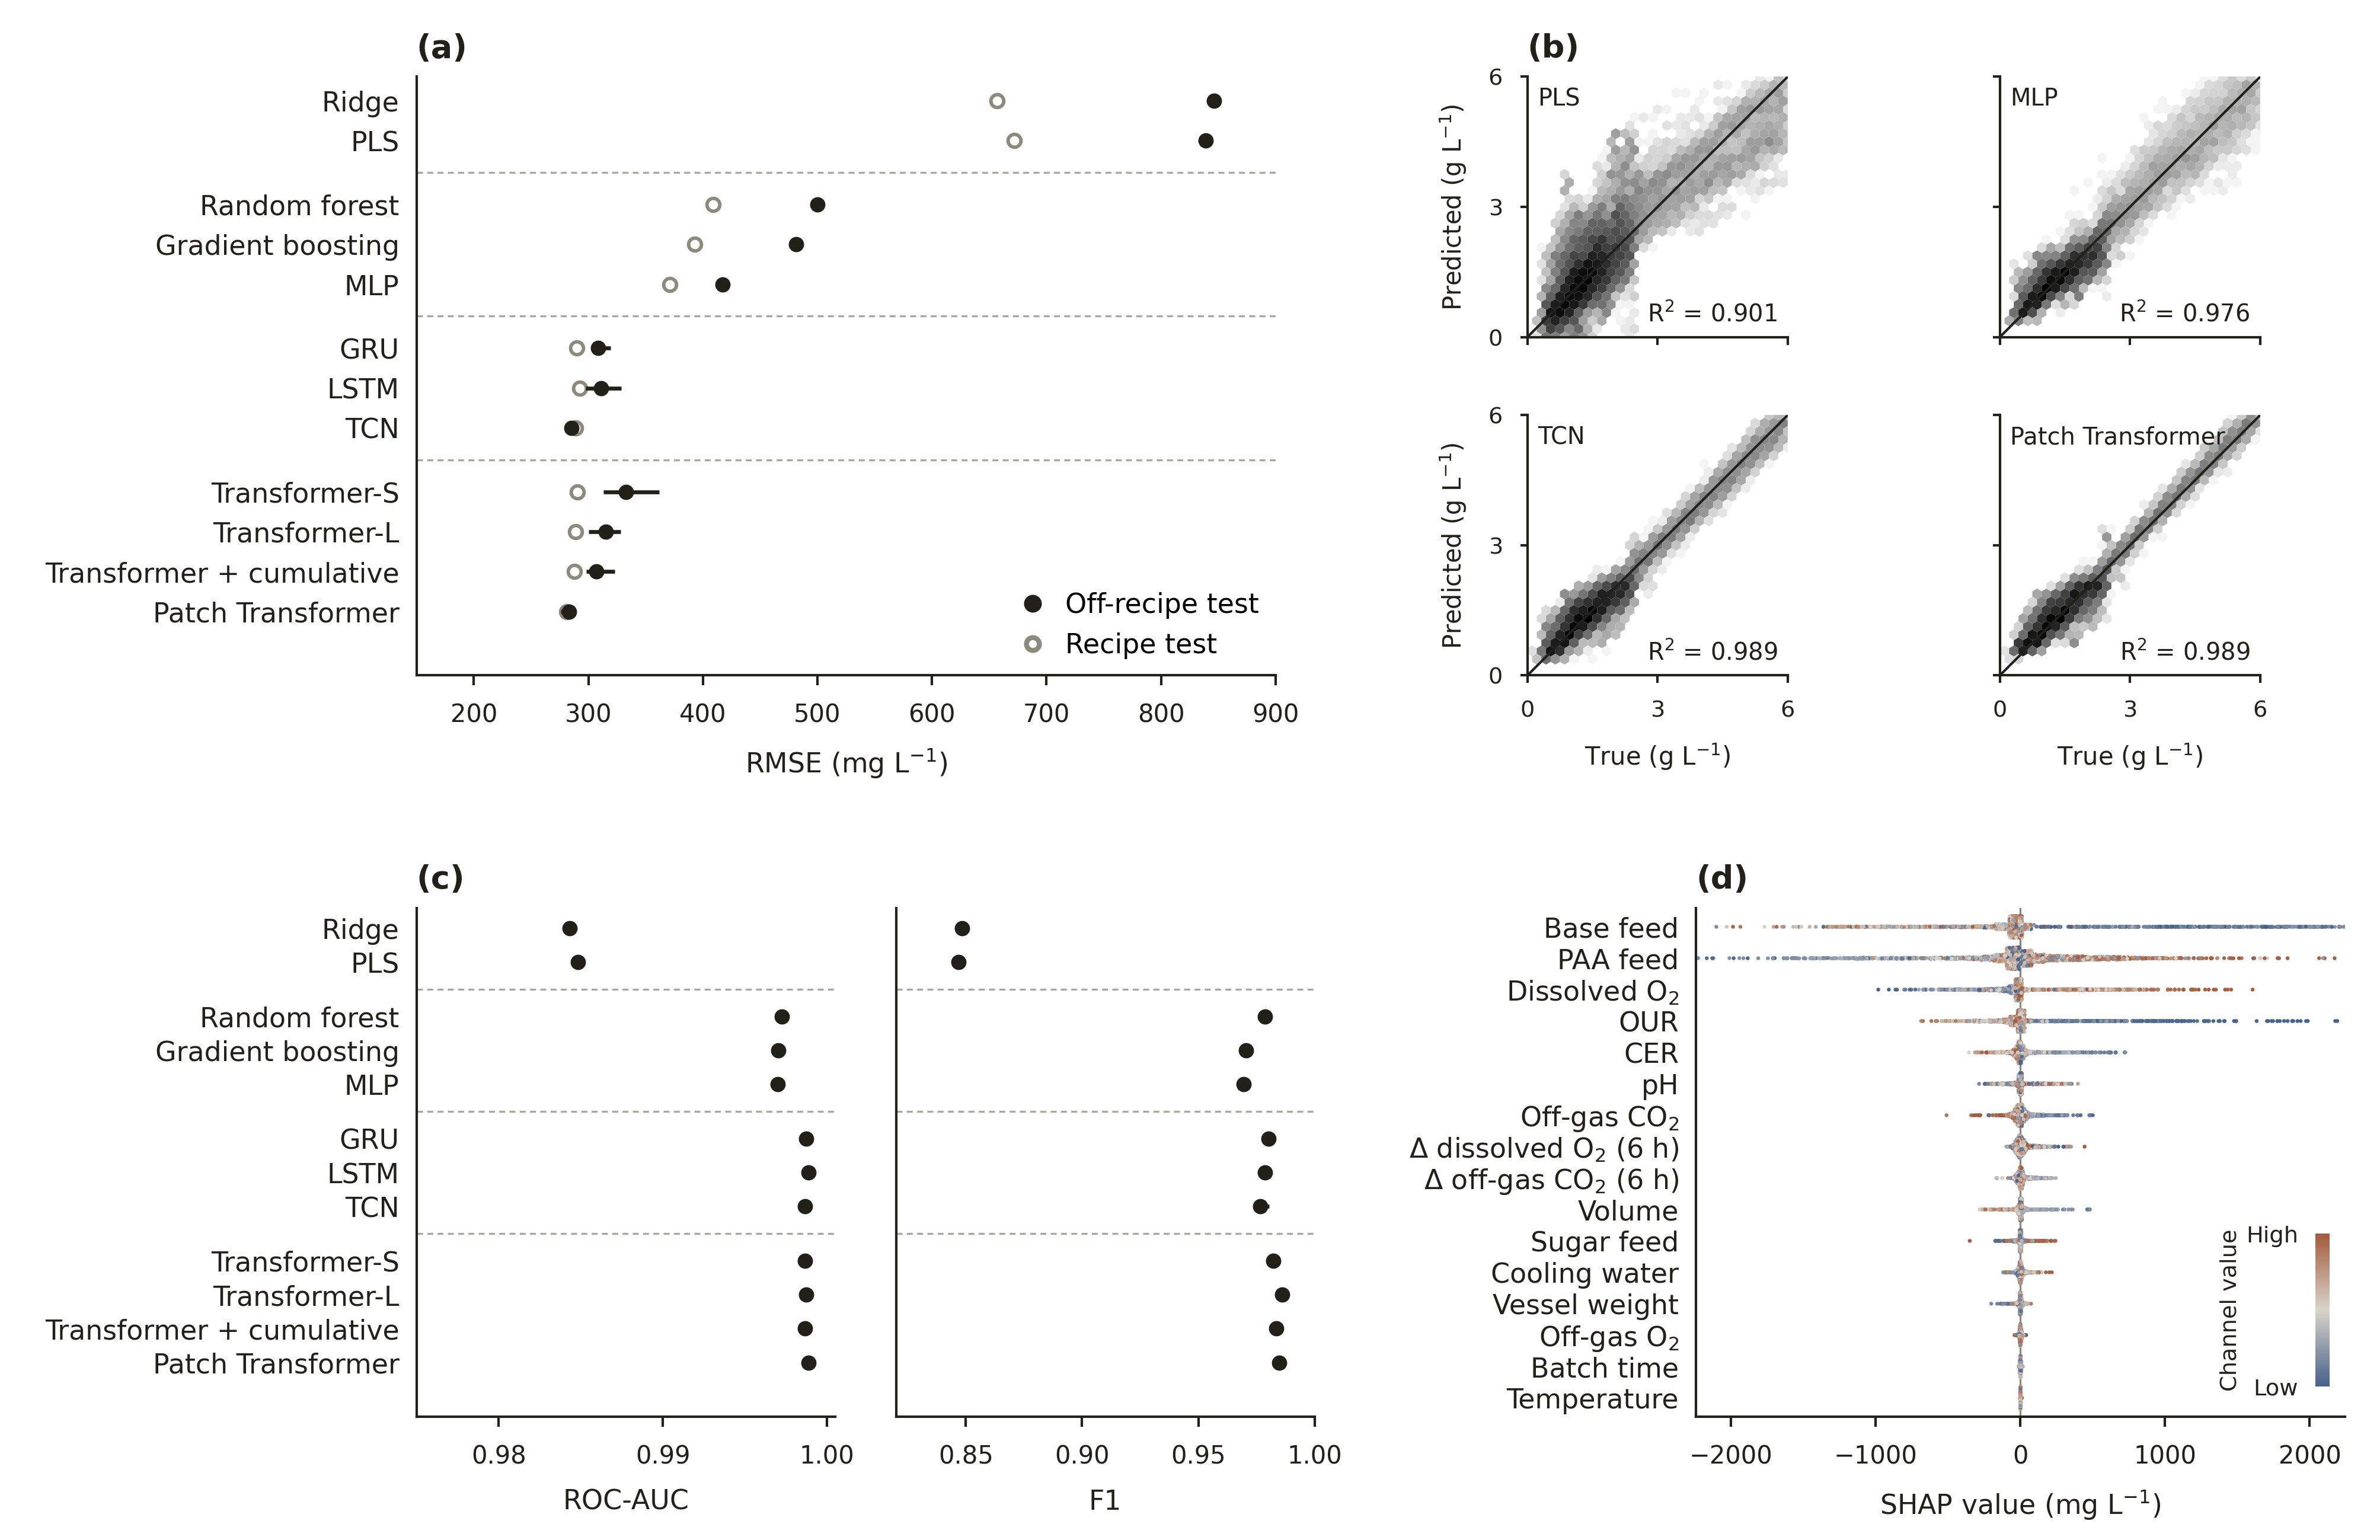

In [7]:
from IPython.display import Image
Image(OUTD + 'fig3.png', width=900)